# Credit Card Fraud Detection ML Pipeline

This notebook implements a fraud detection model using **Logistic Regression** (supervised binary classification) trained on labelled credit card transactions. For each transaction, the model predicts whether it is **fraud (1)** or **normal (0)** and gives a probability of fraud.

**Dataset:** [Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) on Kaggle (`creditcard.csv`)

## Pipeline Steps:

### 1. Setup & Data Loading
- Installs the required libraries (`kagglehub`, `imbalanced-learn`, `seaborn`)
- Downloads the dataset from Kaggle with `kagglehub`
- Loads `creditcard.csv` into a pandas DataFrame

### 2. Exploratory Data Analysis (EDA)
- Checks for missing values
- Counts **fraud vs. normal** transactions (absolute and %)
- Visualises the **class imbalance** with a bar chart
- Compares the `Amount` distribution for fraud and normal transactions

### 3. Data Preparation
- Separates **features** (`Time`, `V1`–`V28`, `Amount`) from the **target** (`Class`)
- **Train/test split**: 80% / 20%, stratified on `Class`
- Scales features with **StandardScaler** (fitted on the training set only)
- Total: **30 numeric features**

### 4. Balancing & Training
- Applies **SMOTE** to the training set only, creating synthetic fraud examples
- Trains a **Logistic Regression** model (`max_iter=1000`, default settings)

### 5. Evaluation
- Predictions on the **untouched test set**
- Metrics: **Accuracy, Precision, Recall, F1, ROC AUC**
- **Confusion matrix** and **ROC curve**
- Conclusions: frauds caught, frauds missed, false alarms

## Key results at a glance

| Metric    | Value  |
|-----------|--------|
| Accuracy  | 0.9741 |
| Precision | 0.0578 |
| Recall    | 0.9184 |
| F1        | 0.1088 |
| ROC AUC   | 0.9708 |

The model catches **90 of the 98 frauds** in the test set (92%) and misses **8**, at the cost of **1,467 false alarms** out of 56,864 normal transactions (2.6%).

---
## 1. Setup & Data Loading

Install the libraries and restart Python so the new packages are available.

In [0]:
%pip install --upgrade kagglehub imbalanced-learn seaborn

In [0]:
# Restart Python on Databricks (skipped on Jupyter / Colab)
try:
    dbutils.library.restartPython()
except NameError:
    pass

Download the dataset from Kaggle and load it into pandas.

In [0]:
import kagglehub
import pandas as pd

path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
print("Path to dataset files:", path)

df = pd.read_csv(f"{path}/creditcard.csv")
df.head()

Path to dataset files: /home/spark-e38b94e6-ca58-47e7-a231-4c/.cache/kagglehub/datasets/mlg-ulb/creditcardfraud/versions/3


In [0]:
print("Rows, columns:", df.shape)

### Results of step 1
- The dataset was downloaded from Kaggle (version 3) and loaded without errors.
- It contains **284,807 transactions** and **31 columns**: `Time`, `V1`–`V28`, `Amount` and the target `Class`.

---
## 2. Exploratory Data Analysis (EDA)

### Missing values

In [0]:
df.isnull().sum()

### Fraud vs. normal transactions

In [0]:
print(df["Class"].value_counts())
print()
print(df["Class"].value_counts(normalize=True) * 100)

Class
0    284315
1       492
Name: count, dtype: int64

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


### Class imbalance chart

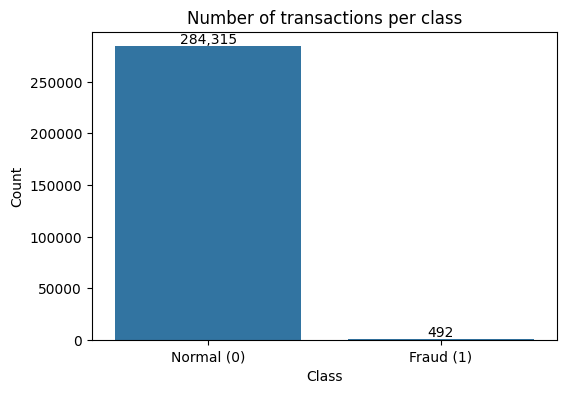

In [0]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
ax = sns.countplot(x="Class", data=df)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Normal (0)", "Fraud (1)"])
ax.set_title("Number of transactions per class")
ax.set_ylabel("Count")

for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.show()

### Amount: fraud vs. normal

In [0]:
df.groupby("Class")["Amount"].describe()

### What I noticed
- Only **492 of 284,807 transactions are fraud (0.17%)**; the other 284,315 (99.83%) are normal.
- In the bar chart the fraud bar is barely visible: the data is **extremely imbalanced**.
- Because of this, a model that always answers "normal" would be **99.83% accurate while catching zero frauds**, so accuracy alone cannot be trusted here. This is why we use SMOTE and look at recall and precision.

---
## 3. Data Preparation

### Features and target

In [0]:
X = df.drop("Class", axis=1)   # inputs
y = df["Class"]                # answer (1 = fraud)

print("X:", X.shape)
print("y:", y.shape)

X: (284807, 30)
y: (284807,)


### Train/test split (80/20, stratified)

`stratify=y` keeps the same small share of fraud in both sets.

In [0]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

X_train: (227845, 30)
X_test:  (56962, 30)
y_train: (227845,)
y_test:  (56962,)


### Feature scaling

The scaler is fitted on the training set only, so no information from the test set leaks into training.

In [0]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # learns mean/std from train only
X_test = scaler.transform(X_test)         # applies the same to test

### Check: fraud share in train and test

In [0]:
print("Fraud in y_train:", y_train.sum(), f"({y_train.mean() * 100:.3f}%)")
print("Fraud in y_test: ", y_test.sum(),  f"({y_test.mean() * 100:.3f}%)")

Fraud in y_train: 394 (0.173%)
Fraud in y_test:  98 (0.172%)


### Results of step 3
- **30 input features** and 1 target column.
- **Training set:** 227,845 transactions, of which **394 frauds** (0.173%).
- **Test set:** 56,962 transactions, of which **98 frauds** (0.172%).
- The fraud share is practically identical in both sets, so the stratified split worked.

---
## 4. Balancing with SMOTE & Training

### SMOTE (training set only)

SMOTE creates synthetic fraud examples so the model has enough fraud to learn from. The test set is never touched.

In [0]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print("Before SMOTE:")
print(y_train.value_counts())
print()
print("After SMOTE:")
print(y_train_bal.value_counts())

Before SMOTE:
Class
0    227451
1       394
Name: count, dtype: int64

After SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64


### Logistic Regression

In [0]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train_bal, y_train_bal)

LogisticRegression(max_iter=1000)

### Results of step 4
- **Before SMOTE:** 227,451 normal vs. 394 fraud in the training set (about 577 normal transactions for every fraud).
- **After SMOTE:** 227,451 normal vs. 227,451 fraud. SMOTE created **227,057 synthetic frauds**, so both classes are now equal.
- The logistic regression trained without errors using the default settings and `max_iter=1000`.

---
## 5. Evaluation

### Predictions on the test set

In [0]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]   # probability of fraud

### Classification report

In [0]:
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

print("Accuracy:", accuracy_score(y_test, y_pred))
print()
print(classification_report(y_test, y_pred, digits=4))
print("ROC AUC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.9741055440469084

              precision    recall  f1-score   support

           0     0.9999    0.9742    0.9869     56864
           1     0.0578    0.9184    0.1088        98

    accuracy                         0.9741     56962
   macro avg     0.5288    0.9463    0.5478     56962
weighted avg     0.9982    0.9741    0.9854     56962

ROC AUC: 0.9708434302252134


### Metrics table

In [0]:
from sklearn.metrics import precision_score, recall_score, f1_score

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC AUC"],
    "Value": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob),
    ],
}).round(4)
metrics

,Metric,Value
0,Accuracy,0.9741
1,Precision,0.0578
2,Recall,0.9184
3,F1,0.1088
4,ROC AUC,0.9708


### Confusion matrix

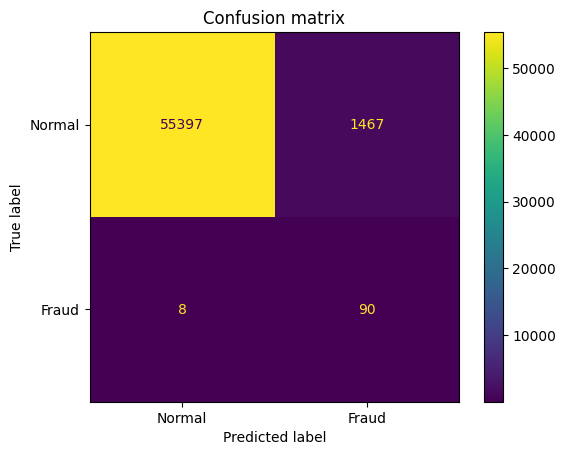

In [0]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Normal", "Fraud"], values_format="d")
plt.title("Confusion matrix")
plt.show()

### ROC curve

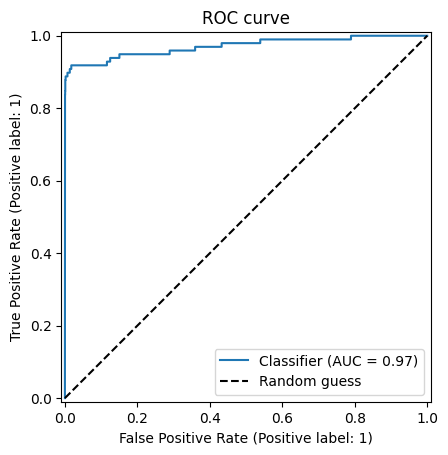

In [0]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.title("ROC curve")
plt.legend()
plt.show()

### Frauds caught, missed and false alarms

In [0]:
from sklearn.metrics import confusion_matrix

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print("Frauds caught (TP):     ", tp)
print("Frauds missed (FN):     ", fn)
print("False alarms (FP):      ", fp)
print("Correct normals (TN):   ", tn)
print("Total frauds in test:   ", tp + fn)

Frauds caught (TP):      90
Frauds missed (FN):      8
False alarms (FP):       1467
Correct normals (TN):    55397
Total frauds in test:    98


### Reading the results

**Confusion matrix (test set, 56,962 transactions)**

|                  | Predicted normal | Predicted fraud |
|------------------|-----------------:|----------------:|
| **Real normal**  | 55,397 (TN)      | 1,467 (FP)      |
| **Real fraud**   | 8 (FN)           | 90 (TP)         |

- **Recall = 0.9184.** Of the 98 real frauds, the model caught 90 (91.8%). This is the most important metric here, and it is high.
- **Precision = 0.0578.** The model raised 1,557 fraud alerts (90 + 1,467), but only 90 were real frauds. That is about **1 real fraud every 17 alerts**, so roughly 94% of the alerts are false alarms.
- **F1 = 0.1088.** It is low because F1 combines recall and precision, and precision is very low.
- **Accuracy = 0.9741.** It looks excellent, but it is *lower* than the 99.83% of a model that always says "normal". This confirms that accuracy is misleading on imbalanced data.
- **ROC AUC = 0.9708.** The model ranks fraudulent transactions above normal ones very well. The ROC curve sits close to the top-left corner, far above the random-guess line.
- **Normal class:** 97.4% of normal transactions are correctly left alone; only 2.6% are wrongly flagged.

---
## Conclusions

The model catches **90 of the 98 frauds** in the test set (recall of about 92%) and misses only **8**. The trade-off is a high number of false alarms: **1,467 normal transactions** were flagged as fraud, so only about 6% of the alerts are real frauds. Accuracy is 97.4%, but it says little here because almost all transactions are normal. With a ROC AUC of 0.97 the model separates the two classes very well, which makes it a good first filter: it finds most frauds, but the flagged transactions still need a second check before acting on them.

### Possible next steps
- **Tune the decision threshold:** raising it above 0.5 would reduce false alarms, at the cost of missing a few more frauds.
- **Try other models**, such as Random Forest or XGBoost, which often reach much higher precision on this dataset.
- **Compare with `class_weight="balanced"`** instead of SMOTE.